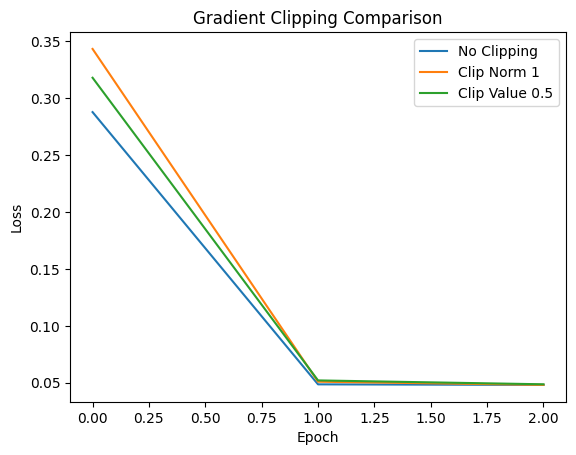

In [6]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

text = "deep learning models learn patterns from data. " * 300

chars = sorted(set(text))
char_to_id = {c:i for i,c in enumerate(chars)}
vocab = len(chars)

sequence = np.array([char_to_id[c] for c in text])

steps = 30

X = np.array([
    sequence[i:i+steps]
    for i in range(len(sequence)-steps-1)
])

Y = np.array([
    sequence[i+1:i+steps+1]
    for i in range(len(sequence)-steps-1)
])

X = tf.keras.utils.to_categorical(X, vocab)
Y = tf.keras.utils.to_categorical(Y, vocab)

configs = [
    ("No Clipping", None, None),
    ("Clip Norm 1", 1.0, None),
    ("Clip Value 0.5", None, 0.5)
]

for name, norm, value in configs:

    model = tf.keras.Sequential([
        tf.keras.layers.Input((steps, vocab)),
        tf.keras.layers.SimpleRNN(64, return_sequences=True),
        tf.keras.layers.Dense(vocab, activation="softmax")
    ])

    optimizer = tf.keras.optimizers.Adam(
        0.02, clipnorm=norm, clipvalue=value
    )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy"
    )

    history = model.fit(
        X[:1500], Y[:1500],
        epochs=3, batch_size=32, verbose=0
    )

    plt.plot(history.history["loss"], label=name)

plt.legend()
plt.title("Gradient Clipping Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()
